[saved] results\figures\fig_perturbation_contrast.png
[saved] results\figures\fig_perturbation_contrast.pdf


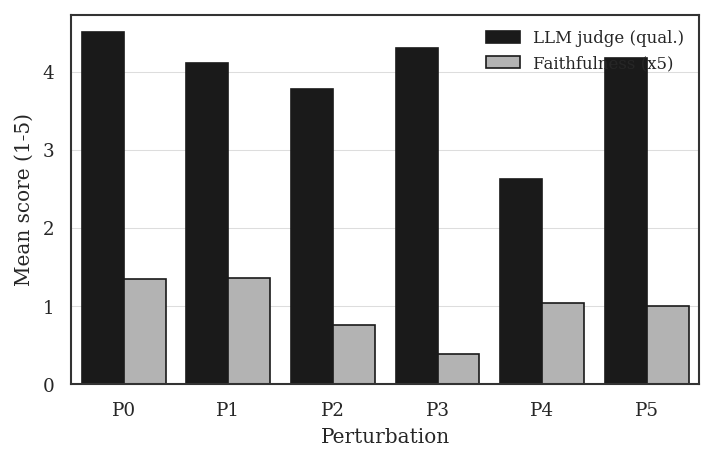

[saved] results\figures\fig_dose_response.png
[saved] results\figures\fig_dose_response.pdf


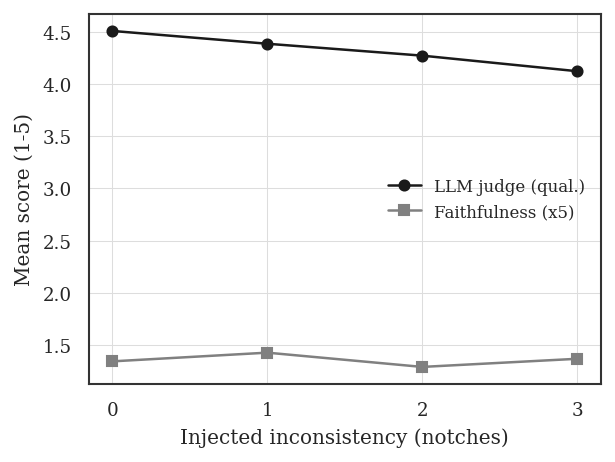

[saved] results\figures\fig_ablation_2x2.png
[saved] results\figures\fig_ablation_2x2.pdf


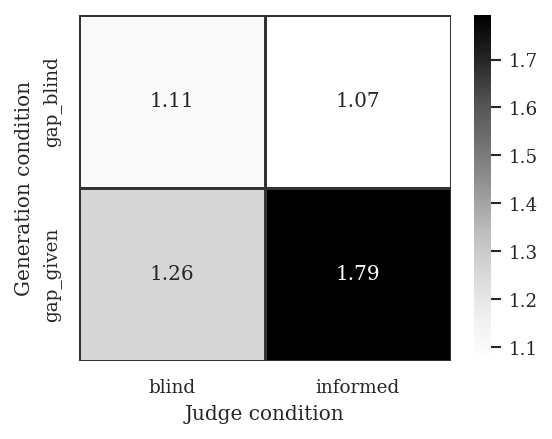

[saved] results\figures\fig_faith_proxy_vs_rag.png
[saved] results\figures\fig_faith_proxy_vs_rag.pdf


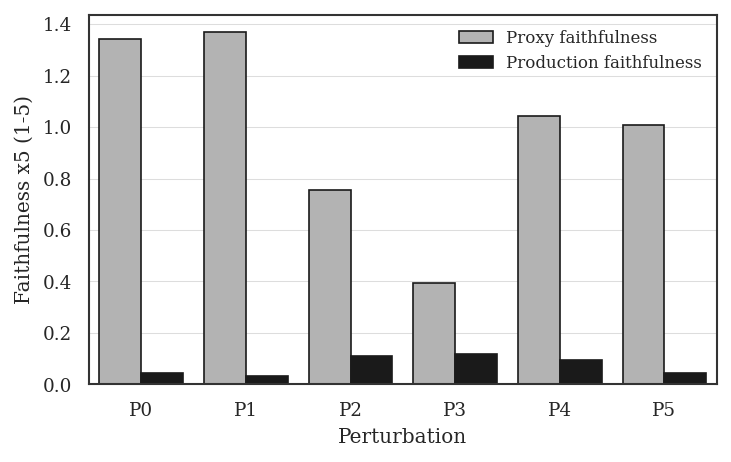

[saved] results\figures\fig_judge_models_p4.png
[saved] results\figures\fig_judge_models_p4.pdf


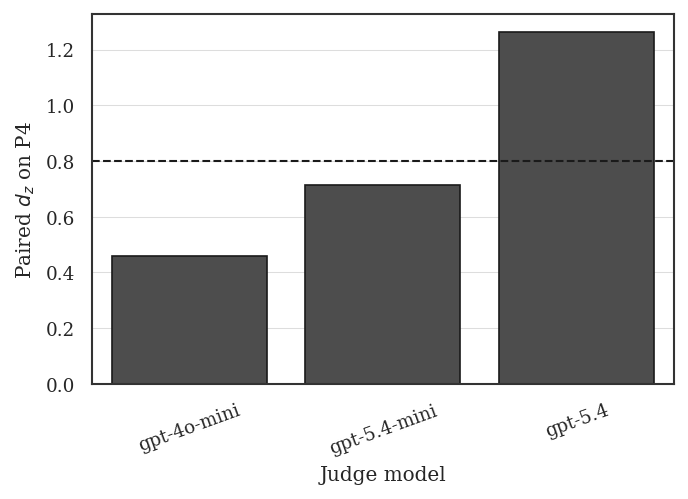

[saved] results\figures\fig_construct_validity.png
[saved] results\figures\fig_construct_validity.pdf


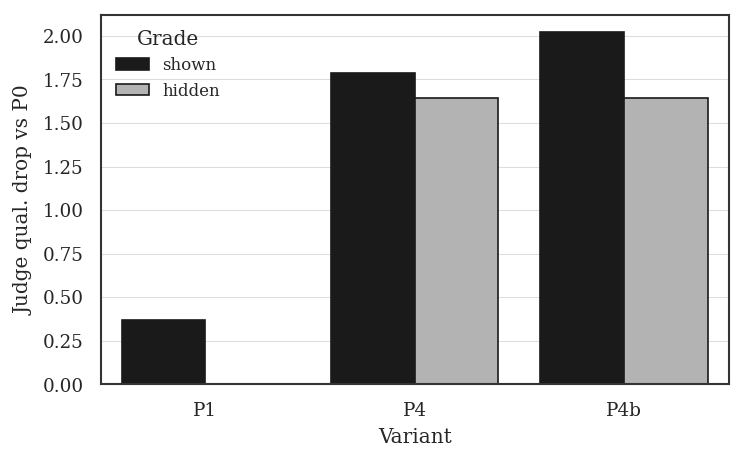

[saved] results\figures\fig_bootstrap_divergence.png
[saved] results\figures\fig_bootstrap_divergence.pdf


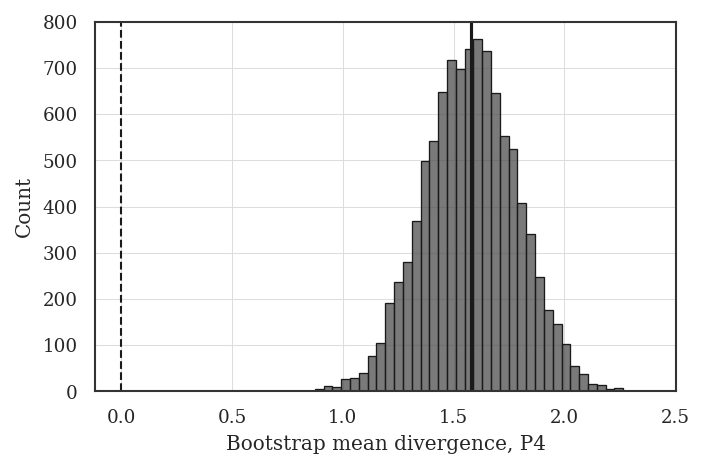

[saved] results\tables\tab_decision_impact.csv
[saved] results\tables\tab_decision_impact.tex
== tab_decision_impact (per-channel Youden thresholds) ==
                                 gate threshold*  invalid_acceptance_rate  valid_rejection_rate  invalid_reaching_human_per100
     metric_gate (proxy faithfulness)        3.0                    0.140                 0.731                           7.02
         judge_gate (LLM judge qual.)        4.0                    0.614                 0.140                          30.70
metric_gate (production faithfulness)        0.0                    1.000                 0.000                          50.00
    combined (judge AND proxy metric)    4.0/3.0                    0.073                 0.784                           3.65
[saved] results\figures\fig_decision_impact.png
[saved] results\figures\fig_decision_impact.pdf


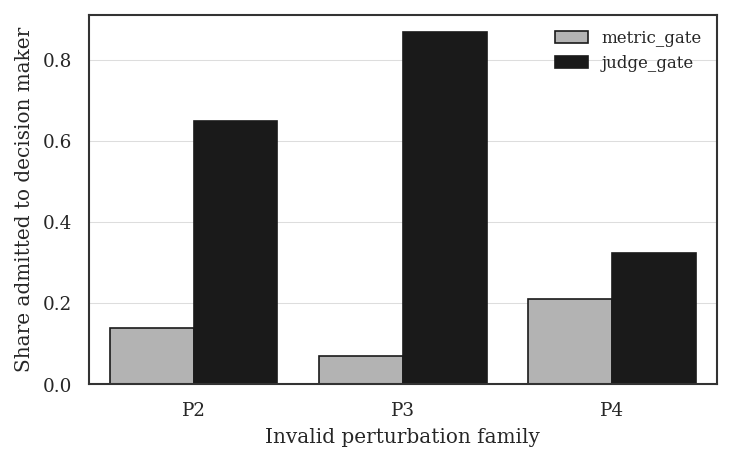


[done] all figures + decision-impact (per-channel thresholds) written. SIMULATION ONLY.


In [2]:
# ============================================================================
# 4_figures.ipynb  —  All figures + decision-impact simulation (OFFLINE, no API)
# ----------------------------------------------------------------------------
# MERGES former 05 (figures) + 07 (decision-impact, PATCHED to per-channel
# thresholds). Reads persisted parquets/tables. All figures grayscale 600 dpi
# PNG+PDF, no captions (manuscript supplies captions).
#
# INPUT   data/scored.parquet, data/judge_models.parquet,
#         data/construct_scored.parquet, results/tables/tab_ablation_2x2.csv
# OUTPUT  results/figures/{fig_perturbation_contrast, fig_dose_response,
#         fig_ablation_2x2, fig_faith_proxy_vs_rag, fig_judge_models_p4,
#         fig_construct_validity, fig_bootstrap_divergence, fig_decision_impact}
#         results/tables/tab_decision_impact.csv
# ============================================================================
import sys, os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd

_HERE = Path.cwd()
_ROOT = _HERE if (_HERE / "src").exists() else _HERE.parent
sys.path.insert(0, str(_ROOT / "src"))
from common import (PROJECT_ROOT, DATA_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR,
                    load_env, set_grayscale_style, save_fig, save_table,
                    require_input, RANDOM_SEED)
import matplotlib.pyplot as plt
import seaborn as sns
set_grayscale_style()
rng = np.random.default_rng(RANDOM_SEED)
warnings.filterwarnings("ignore")

s = pd.read_parquet(require_input(DATA_DIR / "scored.parquet", hint="Run notebook 2 first."))
s["faith5"] = s["faithfulness"] * 5.0
if "faithfulness_rag" in s.columns:
    s["rag5"] = s["faithfulness_rag"] * 5.0
head = s[(s.judge_cond == "informed") & (s.condition == "gap_given")].copy()
order = ["P0", "P1", "P2", "P3", "P4", "P5"]

# ---- Fig 1: per-perturbation contrast (judge qual vs proxy faithfulness x5) --
agg = (head[head.k.isin([0, 3])].groupby("pert")[["judge_qual", "faith5"]].mean().reindex(order).reset_index())
long = agg.melt(id_vars="pert", value_vars=["judge_qual", "faith5"], var_name="channel", value_name="score")
long["channel"] = long["channel"].map({"judge_qual": "LLM judge (qual.)", "faith5": "Faithfulness (x5)"})
fig, ax = plt.subplots(figsize=(5.4, 3.2))
sns.barplot(data=long, x="pert", y="score", hue="channel", palette=["#1a1a1a", "#b3b3b3"], edgecolor="#1a1a1a", ax=ax)
ax.set_xlabel("Perturbation"); ax.set_ylabel("Mean score (1-5)"); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_perturbation_contrast"); plt.show()

# ---- Fig 2: P1 dose-response ------------------------------------------------
dose = (head[head.pert.isin(["P0", "P1"])].assign(notch=lambda d: np.where(d.pert == "P0", 0, d.k))
        .groupby("notch")[["judge_qual", "faith5"]].mean().reset_index())
fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.plot(dose.notch, dose.judge_qual, marker="o", color="#1a1a1a", label="LLM judge (qual.)")
ax.plot(dose.notch, dose.faith5, marker="s", color="#808080", label="Faithfulness (x5)")
ax.set_xlabel("Injected inconsistency (notches)"); ax.set_ylabel("Mean score (1-5)")
ax.set_xticks([0, 1, 2, 3]); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_dose_response"); plt.show()

# ---- Fig 3: 2x2 ablation heatmap (P4 drop) ----------------------------------
abl = pd.read_csv(require_input(TABLES_DIR / "tab_ablation_2x2.csv", hint="Run notebook 3 first."))
mat = abl.pivot(index="generation", columns="judge", values="P4_drop")
fig, ax = plt.subplots(figsize=(4.0, 3.0))
sns.heatmap(mat, annot=True, fmt=".2f", cmap="Greys", cbar=True, linewidths=0.5, linecolor="#333333", ax=ax)
ax.set_xlabel("Judge condition"); ax.set_ylabel("Generation condition")
save_fig(fig, "fig_ablation_2x2"); plt.show()

# ---- Fig 4: proxy vs production faithfulness --------------------------------
if "rag5" in head.columns and head["rag5"].notna().any():
    comp = pd.DataFrame({"proxy_faith5": head[head.k.isin([0, 3])].groupby("pert")["faith5"].mean().reindex(order),
                         "rag_faith5": head[head.k.isin([0, 3])].groupby("pert")["rag5"].mean().reindex(order)}).reset_index()
    long = comp.melt(id_vars="pert", var_name="metric", value_name="score")
    long["metric"] = long["metric"].map({"proxy_faith5": "Proxy faithfulness", "rag_faith5": "Production faithfulness"})
    fig, ax = plt.subplots(figsize=(5.4, 3.2))
    sns.barplot(data=long, x="pert", y="score", hue="metric", palette=["#b3b3b3", "#1a1a1a"], edgecolor="#1a1a1a", ax=ax)
    ax.set_xlabel("Perturbation"); ax.set_ylabel("Faithfulness x5 (1-5)"); ax.legend(frameon=False, fontsize=8)
    save_fig(fig, "fig_faith_proxy_vs_rag"); plt.show()

# ---- Fig 5: judge-model P4 d_z ----------------------------------------------
jm_tab = TABLES_DIR / "tab_judge_models.csv"
if jm_tab.exists():
    p4 = pd.read_csv(jm_tab); p4 = p4[p4.pert == "P4"]
    fig, ax = plt.subplots(figsize=(5.0, 3.2))
    sns.barplot(data=p4, x="judge_model", y="d_z", color="#4d4d4d", edgecolor="#1a1a1a", ax=ax)
    ax.axhline(0.8, color="#1a1a1a", linestyle="--", linewidth=1.0)
    ax.set_xlabel("Judge model"); ax.set_ylabel("Paired $d_z$ on P4"); ax.tick_params(axis="x", rotation=20)
    save_fig(fig, "fig_judge_models_p4"); plt.show()

# ---- Fig 6: construct validity ----------------------------------------------
cst_tab = TABLES_DIR / "tab_construct_validity.csv"
if cst_tab.exists():
    cst = pd.read_csv(cst_tab)
    fig, ax = plt.subplots(figsize=(5.4, 3.2))
    sns.barplot(data=cst, x="pert", y="judge_drop", hue="grade_view", palette=["#1a1a1a", "#b3b3b3"], edgecolor="#1a1a1a", ax=ax)
    ax.set_xlabel("Variant"); ax.set_ylabel("Judge qual. drop vs P0"); ax.legend(title="Grade", frameon=False, fontsize=8)
    save_fig(fig, "fig_construct_validity"); plt.show()

# ---- Fig 7: bootstrap divergence (P4) ---------------------------------------
def paired_div(pert_code):
    p0j = head[head.pert == "P0"].set_index("case_id")["judge_qual"]
    pkj = head[(head.pert == pert_code) & (head.k.isin([0, 3]))].set_index("case_id")["judge_qual"]
    p0m = head[head.pert == "P0"].set_index("case_id")["faith5"]
    pkm = head[(head.pert == pert_code) & (head.k.isin([0, 3]))].set_index("case_id")["faith5"]
    df = pd.DataFrame({"jdrop": p0j - pkj, "mdrop": p0m - pkm}).dropna()
    df["div"] = df["jdrop"] - df["mdrop"]; return df
df4 = paired_div("P4")
boot = [df4["div"].iloc[rng.integers(0, len(df4), len(df4))].mean() for _ in range(10000)]
fig, ax = plt.subplots(figsize=(5.0, 3.2))
sns.histplot(boot, bins=40, color="#4d4d4d", edgecolor="#1a1a1a", ax=ax)
ax.axvline(0.0, color="#1a1a1a", linestyle="--", linewidth=1.0)
ax.axvline(float(np.mean(boot)), color="#1a1a1a", linewidth=1.5)
ax.set_xlabel("Bootstrap mean divergence, P4"); ax.set_ylabel("Count")
save_fig(fig, "fig_bootstrap_divergence"); plt.show()

# ============================================================================
# Decision-impact simulation  (PATCHED: per-channel Youden thresholds)
# ----------------------------------------------------------------------------
# Not a human-subjects study. A deployment gate admits a (rating, rationale) to
# the decision maker iff the channel score clears a threshold. The former fixed
# 3.0 cut is unfair to faithfulness (whose x5 values sit well below 3), so each
# channel now uses its OWN optimal operating point (Youden's J on validity), and
# we also sweep thresholds so the conclusion does not hinge on one cut.
# ============================================================================
from sklearn.metrics import roc_curve
VALID = {"P0": 1, "P1": 1, "P5": 1, "P2": 0, "P3": 0, "P4": 0}
INVALID_FAMILIES = ["P2", "P3", "P4"]
d = head[head.k.isin([0, 3])].copy()
d["valid"] = d["pert"].map(VALID)
d = d.dropna(subset=["valid"])

channels = {"metric_gate (proxy faithfulness)": "faith5", "judge_gate (LLM judge qual.)": "judge_qual"}
if "rag5" in d.columns and d["rag5"].notna().any():
    channels["metric_gate (production faithfulness)"] = "rag5"

def youden_threshold(scores, valid):
    valid = np.asarray(valid); scores = np.asarray(scores, float)
    if len(np.unique(valid)) < 2:
        return float(np.median(scores))
    fpr, tpr, thr = roc_curve(valid, scores)   # high score => looks valid
    finite = np.isfinite(thr)                   # drop sklearn's +inf sentinel
    if not finite.any():
        return float(np.median(scores))
    fpr, tpr, thr = fpr[finite], tpr[finite], thr[finite]
    return float(thr[np.argmax(tpr - fpr)])

rows = []
thr_by_channel = {}
for name, col in channels.items():
    dd = d.dropna(subset=[col])
    t = youden_threshold(dd[col], dd["valid"]); thr_by_channel[name] = t
    acc = dd[col] >= t; inv = dd["valid"] == 0; val = dd["valid"] == 1
    rows.append({"gate": name, "threshold*": round(t, 3),
                 "invalid_acceptance_rate": round(float((acc & inv).sum()) / max(1, int(inv.sum())), 3),
                 "valid_rejection_rate": round(float((~acc & val).sum()) / max(1, int(val.sum())), 3),
                 "invalid_reaching_human_per100": round(100.0 * float((acc & inv).sum()) / max(1, len(dd)), 2)})
# combined gate at each channel's own Youden threshold
dd = d.dropna(subset=["judge_qual", "faith5"])
tj, tm = thr_by_channel["judge_gate (LLM judge qual.)"], thr_by_channel["metric_gate (proxy faithfulness)"]
acc = (dd["judge_qual"] >= tj) & (dd["faith5"] >= tm); inv = dd["valid"] == 0; val = dd["valid"] == 1
rows.append({"gate": "combined (judge AND proxy metric)", "threshold*": f"{round(tj,2)}/{round(tm,2)}",
             "invalid_acceptance_rate": round(float((acc & inv).sum()) / max(1, int(inv.sum())), 3),
             "valid_rejection_rate": round(float((~acc & val).sum()) / max(1, int(val.sum())), 3),
             "invalid_reaching_human_per100": round(100.0 * float((acc & inv).sum()) / max(1, len(dd)), 2)})
dim = pd.DataFrame(rows); save_table(dim, "tab_decision_impact")
print("== tab_decision_impact (per-channel Youden thresholds) =="); print(dim.to_string(index=False))

# per-family admitted-invalid share at each channel's threshold
fam_rows = []
for fam in INVALID_FAMILIES:
    df = d[d.pert == fam]
    for name, col in [("metric_gate", "faith5"), ("judge_gate", "judge_qual")]:
        t = thr_by_channel["metric_gate (proxy faithfulness)"] if col == "faith5" else thr_by_channel["judge_gate (LLM judge qual.)"]
        dd2 = df.dropna(subset=[col])
        if len(dd2):
            fam_rows.append({"family": fam, "gate": name, "accepted_invalid_rate": round(float((dd2[col] >= t).mean()), 3)})
fam = pd.DataFrame(fam_rows)
fig, ax = plt.subplots(figsize=(5.4, 3.2))
sns.barplot(data=fam, x="family", y="accepted_invalid_rate", hue="gate", palette=["#b3b3b3", "#1a1a1a"], edgecolor="#1a1a1a", ax=ax)
ax.set_xlabel("Invalid perturbation family"); ax.set_ylabel("Share admitted to decision maker"); ax.legend(frameon=False, fontsize=8)
save_fig(fig, "fig_decision_impact"); plt.show()
print("\n[done] all figures + decision-impact (per-channel thresholds) written. SIMULATION ONLY.")
